In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

"""
4. Food Delivery Time Analysis (food_delivery.csv, 888 orders)
Question: "What makes deliveries late, and how does delay affect ratings?"

Spot the 5 outliers in delivery time with the IQR method in NumPy, then decide whether to remove them.
Fill the missing ratings.
Create an is_late column for deliveries over 45 minutes.
Show delivery time by traffic, weather, and time of day in box plots.
Plot distance against delivery time with a regression line.
Plot delivery time against rating.
Use np.polyfit to predict delivery time from distance.
"""

'\n4. Food Delivery Time Analysis (food_delivery.csv, 888 orders)\nQuestion: "What makes deliveries late, and how does delay affect ratings?"\n\nSpot the 5 outliers in delivery time with the IQR method in NumPy, then decide whether to remove them.\nFill the missing ratings.\nCreate an is_late column for deliveries over 45 minutes.\nShow delivery time by traffic, weather, and time of day in box plots.\nPlot distance against delivery time with a regression line.\nPlot delivery time against rating.\nUse np.polyfit to predict delivery time from distance.\n'

In [3]:
df = pd.read_csv("C:/Users/HP/Downloads/food_delivery.csv")
df.head()

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4


In [8]:
df["delivery_time"] = df["delivery_time_min"]
df.head()

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating,delivery_time
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4,39.0
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9,50.0
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1,60.0
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0,10.0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4,24.0


In [20]:
q1 = np.percentile(df["delivery_time"], 25)
q3 = np.percentile(df["delivery_time"], 75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (df["delivery_time"] < lower_bound) | (df["delivery_time"] > upper_bound)
outliers = df[outlier_mask]
df = df[~outlier_mask].reset_index(drop=True)

In [21]:
df 

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating,delivery_time
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4,39.0
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9,50.0
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1,60.0
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0,10.0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4,24.0
...,...,...,...,...,...,...,...,...,...
760,5796,0.5,14.0,Medium,Clear,Morning,20.0,5.0,20.0
761,5797,8.2,20.0,Low,Clear,Afternoon,57.0,4.2,57.0
762,5798,5.4,10.0,Low,Clear,Afternoon,33.0,5.0,33.0
763,5799,5.0,15.0,Low,Rain,Evening,36.0,4.8,36.0


In [24]:
df.isnull().sum()
df["rating"] = df["rating"].fillna(df["rating"].median())
df.isnull().sum()

order_id             0
distance_km          0
prep_time_min        0
traffic              0
weather              0
time_of_day          0
delivery_time_min    0
rating               0
delivery_time        0
dtype: int64

In [28]:
df["is_late"] =(df["delivery_time"] >= 45 )
df

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating,delivery_time,is_late
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4,39.0,False
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9,50.0,True
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1,60.0,True
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0,10.0,False
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4,24.0,False
...,...,...,...,...,...,...,...,...,...,...
760,5796,0.5,14.0,Medium,Clear,Morning,20.0,5.0,20.0,False
761,5797,8.2,20.0,Low,Clear,Afternoon,57.0,4.2,57.0,True
762,5798,5.4,10.0,Low,Clear,Afternoon,33.0,5.0,33.0,False
763,5799,5.0,15.0,Low,Rain,Evening,36.0,4.8,36.0,False


Text(0.5, 1.0, 'by traffic')

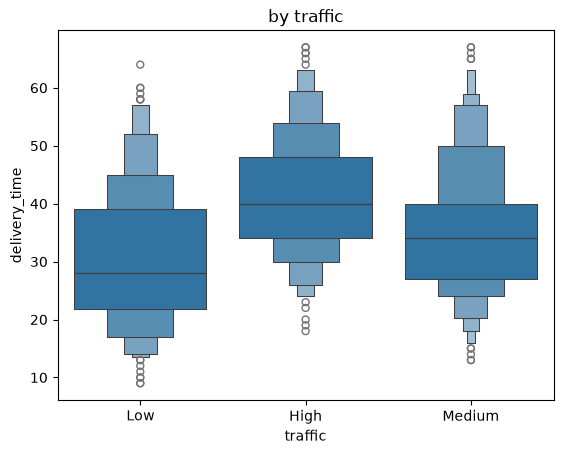

In [29]:
ax = sns.boxenplot(data = df, x = "traffic", y = "delivery_time")
ax.set_title( "by traffic")

Text(0.5, 1.0, 'by traffic')

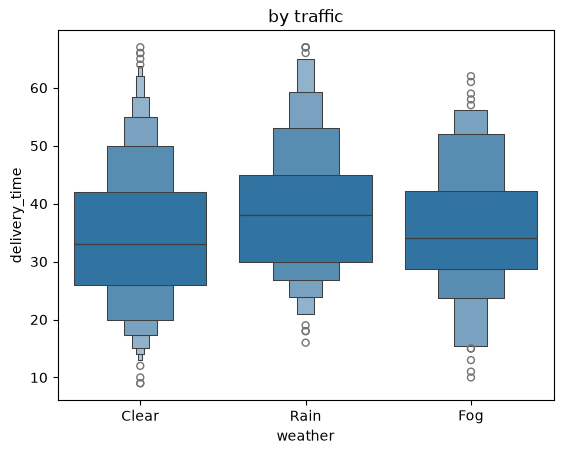

In [46]:
ax = sns.boxenplot(data = df, x = "weather", y = "delivery_time")
ax.set_title( "by traffic")

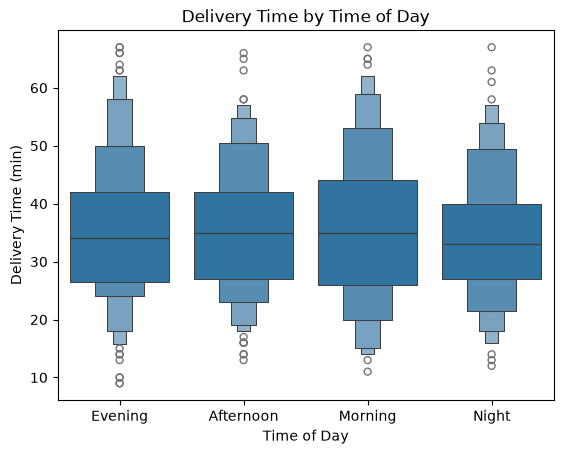

In [48]:
ax = sns.boxenplot(data=df, x="time_of_day", y="delivery_time")
ax.set_title("Delivery Time by Time of Day")
ax.set_xlabel("Time of Day")
ax.set_ylabel("Delivery Time (min)")
plt.show()

Text(0.5, 1.0, 'distance vs delivery_time')

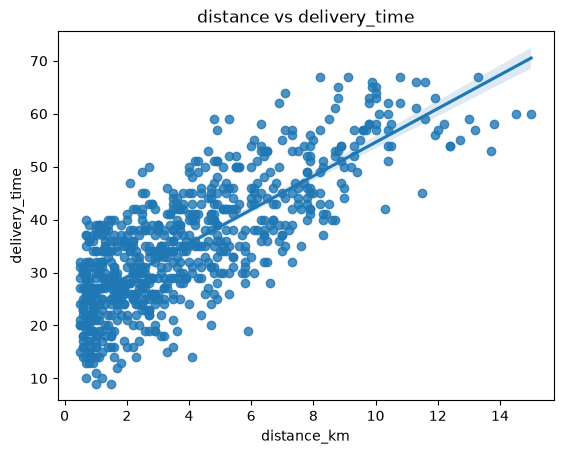

In [44]:
ax=sns.regplot(data = df, x ="distance_km" , y = "delivery_time")
ax.set_title("distance vs delivery_time")

Text(0.5, 1.0, 'rating as delivery_time')

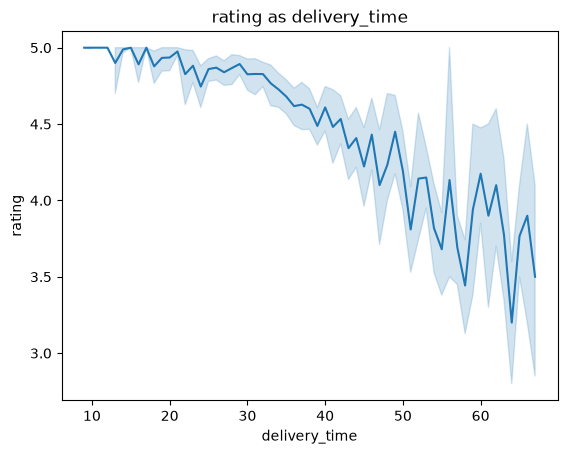

In [39]:
ax = sns.lineplot(data = df , x = "delivery_time" , y = "rating")
ax.set_title("rating as delivery_time")